# 53 — Random surface patch QC (supplementary table + figure)

Reviewer request: summary statistics for patch size distributions and overlap with the true ligand-binding sites.

Thin wrapper around `scripts/patch_qc_stats.py`; all logic lives there. Population = nb52 pooled screening set
(cross-dataset dedup on `(pdb_id, lig_resname)`, priority COACH420 > scPDB > PDBbind > HOLO4K, valid & in CCD library):
13,723 complexes, 15,533 pockets, 252,222 patches.

Per-patch and per-pocket stats are cached in `RESULTS/patch_qc/`; delete `patch_qc_per_patch.tsv` /
`observed_site_residues.tsv` to recompute from the LMDBs and raw structures.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT = Path.cwd().parent / 'DATA' / 'drugclip'
sys.path.insert(0, str(Path.cwd() / 'drugclip_scripts'))
import patch_qc_stats as q

OUT = q.OUT_DIR

## 1. Run (uses cached per-patch / per-pocket tables if present)

manifest vs LMDB atom-count mismatches: 0



=== patch_qc_summary.tsv
Dataset                                                   COACH420            HOLO4K             scPDB           PDBbind            Pooled
Complexes                                                      256              3529              4901              5037             13723
Ligand pockets                                                 330              5265              4901              5037             15533
Patches                                                       3579             64414            102044             82185            252222
Patches / complex, median [IQR]                          13 [9–17]        16 [11–22]        18 [13–25]        14 [10–19]        16 [11–22]
Heavy atoms / patch, median [IQR]                    127 [124–134]     127 [124–135]     127 [124–134]     127 [124–134]     127 [124–135]
Heavy atoms / patch, min–max                                 5–218             4–229             4–239             4–231             4–239
R

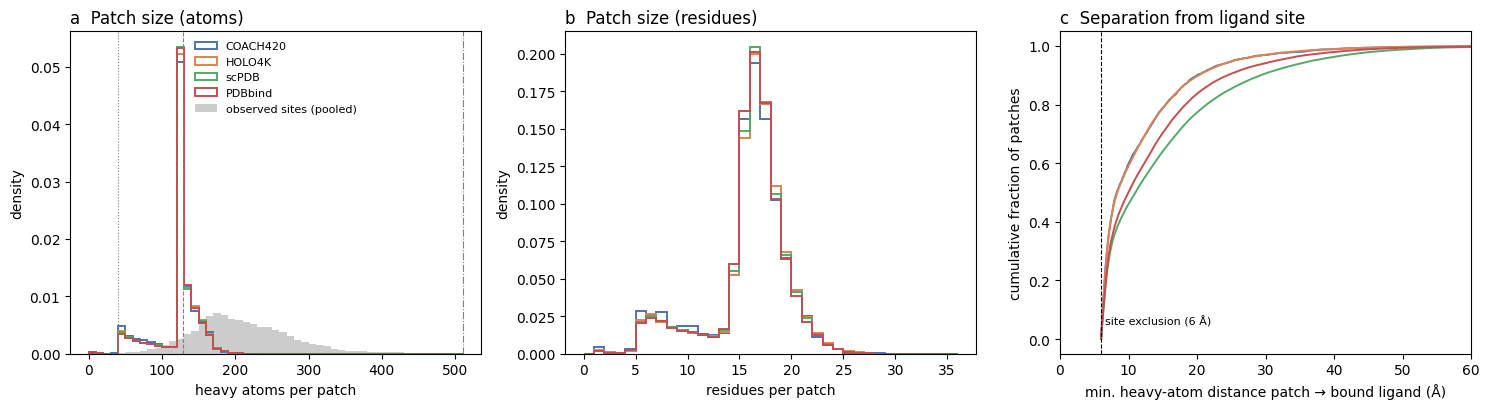

In [2]:
q.main()

## 2. Supplementary table — screening population (median [IQR])

In [3]:
summary = pd.read_csv(OUT / 'patch_qc_summary.tsv', sep='\t', index_col='Statistic')
summary

,COACH420,HOLO4K,scPDB,PDBbind,Pooled
Statistic,,,,,
Complexes,256,3529,4901,5037,13723
Ligand pockets,330,5265,4901,5037,15533
Patches,3579,64414,102044,82185,252222
"Patches / complex, median [IQR]",13 [9–17],16 [11–22],18 [13–25],14 [10–19],16 [11–22]
"Heavy atoms / patch, median [IQR]",127 [124–134],127 [124–135],127 [124–134],127 [124–134],127 [124–135]
"Heavy atoms / patch, min–max",5–218,4–229,4–239,4–231,4–239
"Residues / patch, median [IQR]",16 [15–18],16 [15–18],16 [15–18],16 [15–18],16 [15–18]
"Residues / patch, min–max",1–28,1–31,1–35,1–30,1–35
Patches < 40 atoms (%),0.59,0.35,0.26,0.22,0.28


Same table over all 277,306 generated patches (before dedup), for reference:

In [4]:
pd.read_csv(OUT / 'patch_qc_summary_all.tsv', sep='\t', index_col='Statistic')

,COACH420,HOLO4K,scPDB,PDBbind,Pooled
Statistic,,,,,
Complexes,265,4639,5019,5316,15239
Ligand pockets,335,6690,4967,5313,17305
Patches,3709,82548,104225,86824,277306
"Patches / complex, median [IQR]",13 [9–17],15 [11–21],18 [13–25],14 [10–19],15 [11–22]
"Heavy atoms / patch, median [IQR]",127 [124–134],127 [124–135],127 [124–134],127 [124–135],127 [124–135]
"Heavy atoms / patch, min–max",5–237,4–237,4–239,4–231,4–239
"Residues / patch, median [IQR]",16 [15–18],16 [15–18],16 [15–18],16 [15–18],16 [15–18]
"Residues / patch, min–max",1–33,1–33,1–35,1–30,1–35
Patches < 40 atoms (%),0.57,0.36,0.27,0.22,0.28


## 3. Figure

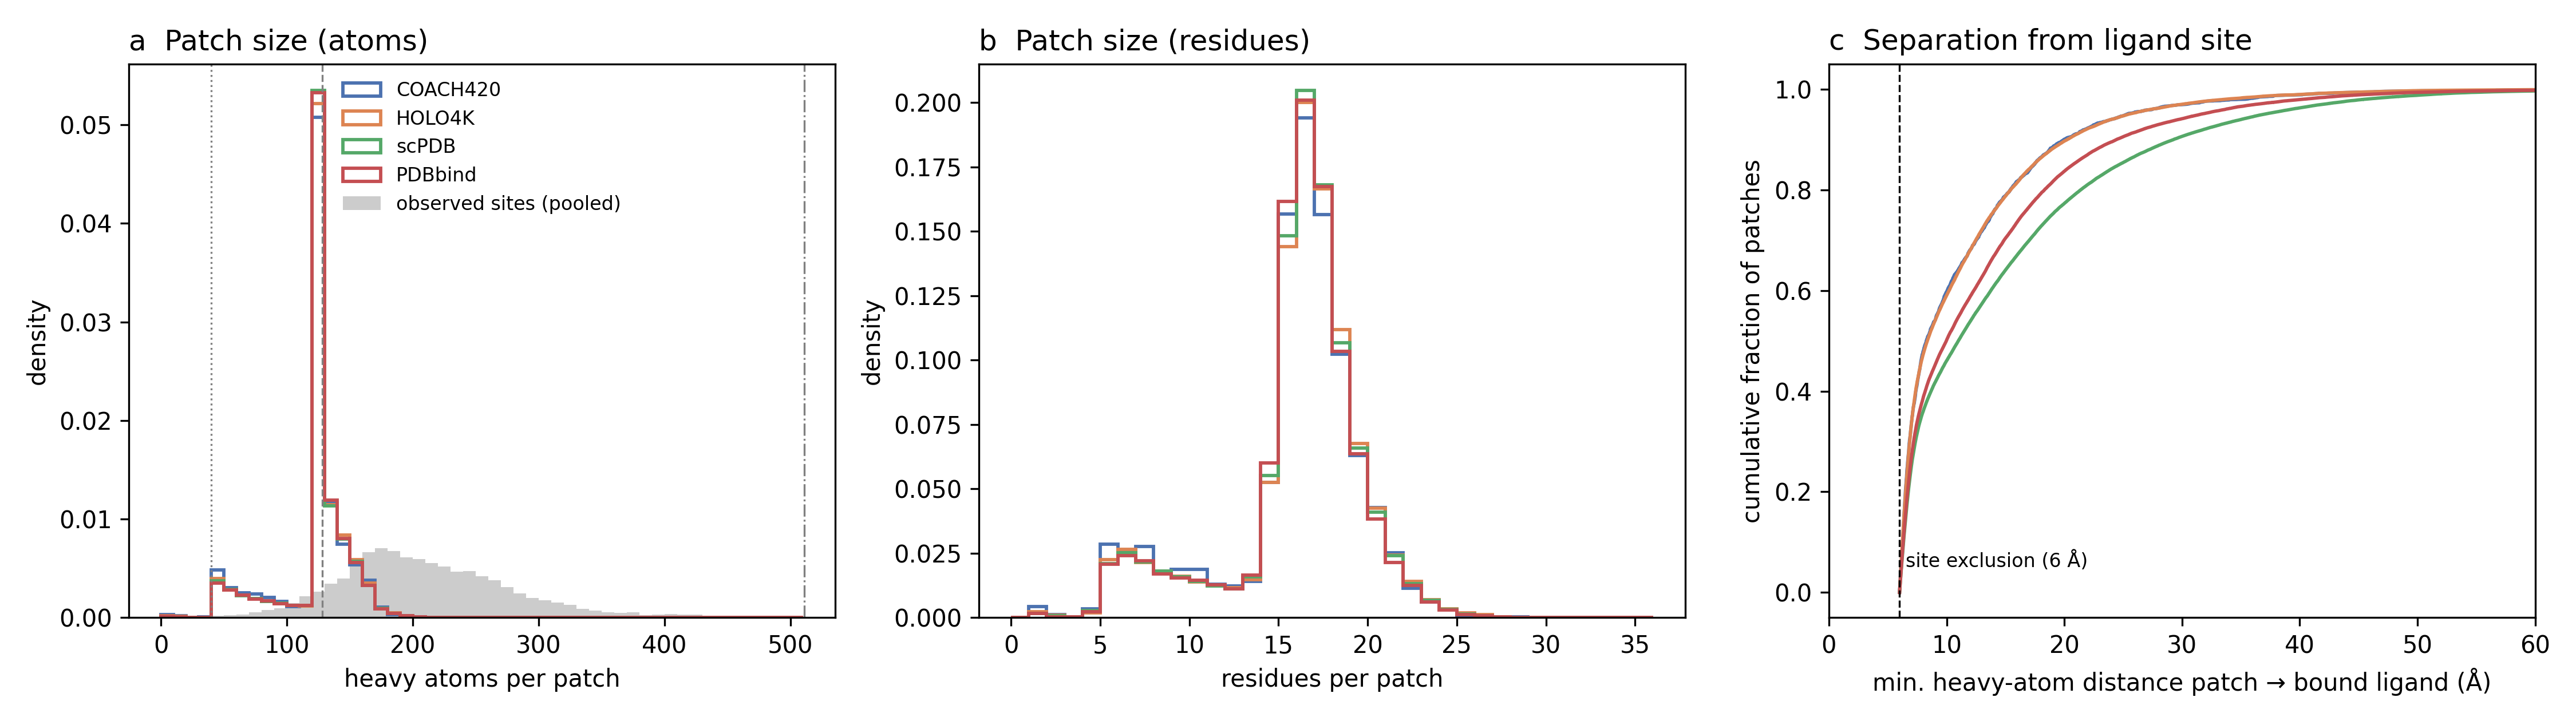

In [5]:
display(Image(filename=str(OUT / 'fig_patch_qc.png'), width=1100))

## 4. Distributions — screening population

Square, one figure per quantity, same colour code as nb50: patches black, experimental pockets green (`#2CA02C`).
Y axis = % of items. Values above 60 (count or Å) are clipped into the last bin. Dashed lines: grey = construction thresholds (40 / 128 atoms in (b); 6 Å site exclusion in (d));
coloured = median of each distribution (computed on unclipped values). Integer y ticks.

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# ── Data: screening population (252,222 patches / 15,533 pockets) ─────────────
per_patch = pd.read_csv(OUT / 'patch_qc_per_patch.tsv', sep='\t')
pop = q.screening_population()
entries = set(zip(pop.dataset, pop.entry))
patches = per_patch[[k in entries for k in zip(per_patch.dataset, per_patch.complex_id)]]
site = q.observed_site_residues(pop)
per_cx = patches.groupby(['dataset', 'complex_id']).size()

print(f'patches={len(patches):,}  complexes={len(per_cx):,}  pockets={len(pop):,}')
assert len(patches) == 252_222

patches=252,222  complexes=13,723  pockets=15,533


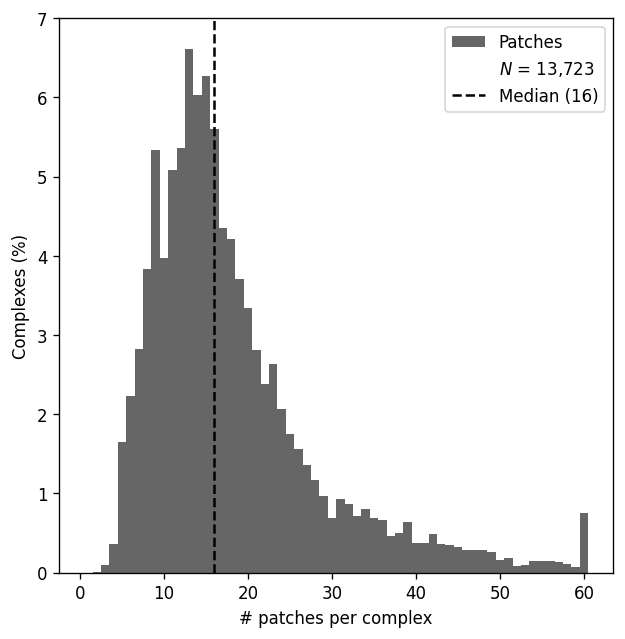

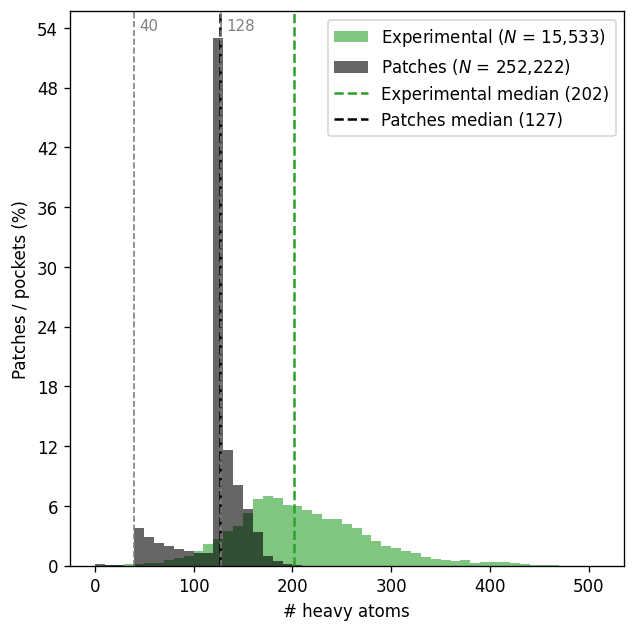

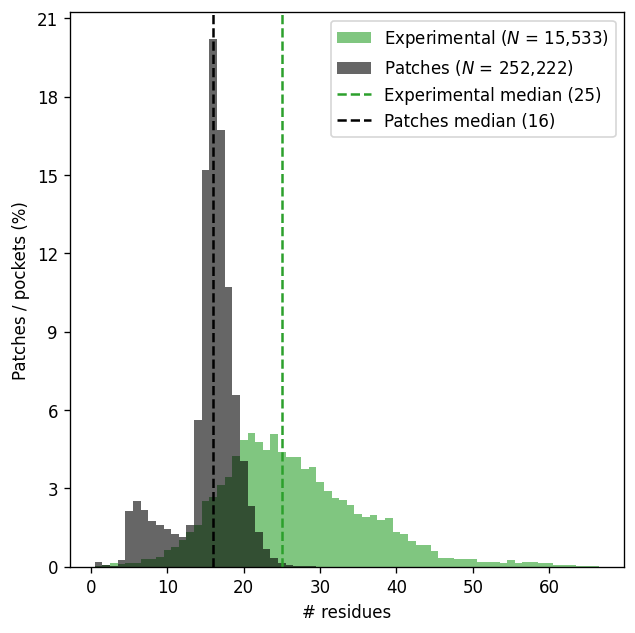

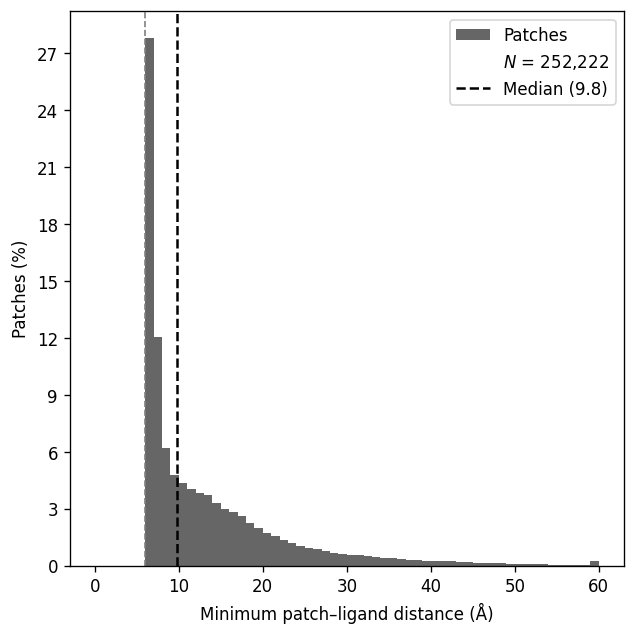

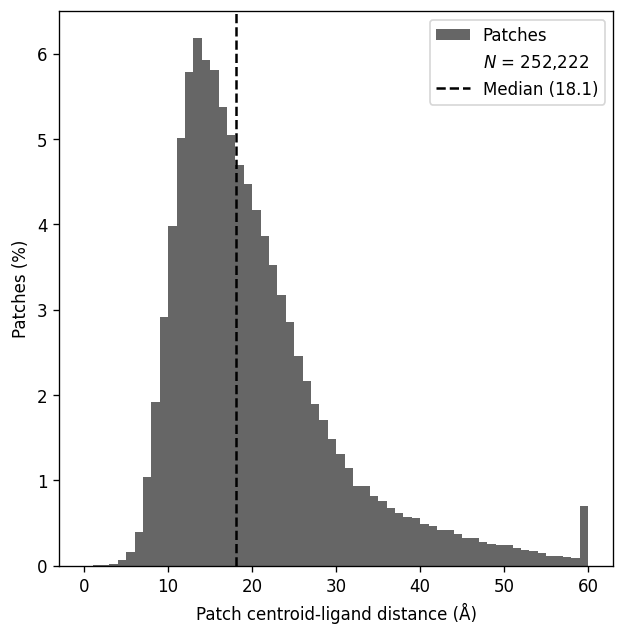

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MaxNLocator

PATCH_C  = '#000000'   # 'patches' in nb42 / nb50
SOURCE_C = '#2CA02C'   # 'bound' / Experimental in nb42 / nb50
ALPHA = 0.6
CLIP = 60

plt.rcParams.update({'figure.dpi': 120, 'font.size': 10,
                     'axes.spines.top': True, 'axes.spines.right': True})


def pct_hist(ax, vals, bins, **kwargs):
    vals = np.asarray(vals)
    weights = np.full(len(vals), 100.0 / len(vals)) if len(vals) else None
    return ax.hist(vals, bins=bins, weights=weights, **kwargs)


def n_handle(n):
    return Patch(color='none', label=f'$N$ = {n:,}')


def square_fig():
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_box_aspect(1)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    return fig, ax


def save(fig, name):
    for ext in ('png', 'pdf'):
        fig.savefig(OUT / f'{name}.{ext}', dpi=600, bbox_inches='tight')
    plt.show()


def single(vals, bins, xlabel, ylabel, label, name, vline=None, median_of=None, fmt='.0f', ymax=None):
    """median_of: unclipped values for the median (vals may be clipped for plotting)."""
    fig, ax = square_fig()
    pct_hist(ax, vals, bins, alpha=ALPHA, color=PATCH_C, label=label)
    if vline is not None:
        ax.axvline(vline, color='grey', ls='--', lw=1)
    med = float(np.median(vals if median_of is None else median_of))
    ax.axvline(med, color=PATCH_C, ls='--', lw=1.5)
    if ymax is not None:
        ax.set_ylim(top=ymax)
    h, _ = ax.get_legend_handles_labels()
    h += [n_handle(len(vals)),
          Line2D([], [], color=PATCH_C, ls='--', lw=1.5, label=f'Median ({med:{fmt}})')]
    ax.legend(handles=h, fontsize=10)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    save(fig, name)


def paired(patch_vals, pocket_vals, bins, xlabel, name, guides=()):
    fig, ax = square_fig()
    pct_hist(ax, pocket_vals, bins, alpha=ALPHA, color=SOURCE_C,
             label=f'Experimental ($N$ = {len(pocket_vals):,})')
    pct_hist(ax, patch_vals, bins, alpha=ALPHA, color=PATCH_C,
             label=f'Patches ($N$ = {len(patch_vals):,})')
    # Medians: dashed, in each distribution's colour
    for vals, col in [(pocket_vals, SOURCE_C), (patch_vals, PATCH_C)]:
        ax.axvline(np.median(vals), color=col, ls='--', lw=1.5)
    # Construction thresholds (e.g. 40 / 128 atoms): dashed grey, labelled at the top
    for g in guides:
        ax.axvline(g, color='grey', ls='--', lw=1)
        ax.annotate(f'{g}', (g, 1), xycoords=('data', 'axes fraction'), xytext=(3, -4),
                    textcoords='offset points', ha='left', va='top', fontsize=9, color='grey')
    h, _ = ax.get_legend_handles_labels()
    h += [Line2D([], [], color=SOURCE_C, ls='--', lw=1.5, label=f'Experimental median ({np.median(pocket_vals):.0f})'),
          Line2D([], [], color=PATCH_C, ls='--', lw=1.5, label=f'Patches median ({np.median(patch_vals):.0f})')]
    ax.legend(handles=h, fontsize=10)
    ax.set_xlabel(xlabel); ax.set_ylabel('Patches / pockets (%)')
    save(fig, name)


# a  patches per complex
single(per_cx.clip(upper=CLIP), np.arange(0.5, CLIP + 1.5, 1),
       f'# patches per complex', 'Complexes (%)', 'Patches', 'fig_patch_qc_a_patches_per_complex',
       median_of=per_cx, ymax=7)

# b  heavy atoms: patches vs experimental pockets
paired(patches.n_atoms, pop.n_pocket_atoms, np.arange(0, 520, 10),
       '# heavy atoms', 'fig_patch_qc_b_heavy_atoms', guides=(40, 128))

# c  residues: patches vs experimental pockets
paired(patches.n_residues, site.n_site_residues,
       np.arange(0.5, max(patches.n_residues.max(), site.n_site_residues.max()) + 1.5, 1),
       '# residues', 'fig_patch_qc_c_residues')

# d  minimum patch–ligand distance (dashed line: 6 Å site exclusion)
single(patches.min_dist_to_ligand.clip(upper=CLIP), np.arange(0, CLIP + 1, 1),
       f'Minimum patch–ligand distance (Å)', 'Patches (%)', 'Patches',
       'fig_patch_qc_d_min_distance', vline=q.LIGAND_CUTOFF,
       median_of=patches.min_dist_to_ligand, fmt='.1f')

# e  patch centroid–ligand distance
single(patches.centroid_dist_to_ligand.clip(upper=CLIP), np.arange(0, CLIP + 1, 1),
       f'Patch centroid-ligand distance (Å)', 'Patches (%)', 'Patches',
       'fig_patch_qc_e_centroid_distance',
       median_of=patches.centroid_dist_to_ligand, fmt='.1f')

In [8]:
# Share of values beyond the plotted range (clipped into the last bin)
print(f'min distance > 60 Å:      {100 * (patches.min_dist_to_ligand > 60).mean():.2f}%')
print(f'centroid distance > 60 Å: {100 * (patches.centroid_dist_to_ligand > 60).mean():.2f}%')
print(f'patches/complex > {CLIP}:     {100 * (per_cx > CLIP).mean():.2f}%')

min distance > 60 Å:      0.22%
centroid distance > 60 Å: 0.61%
patches/complex > 60:     0.70%
